In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from underthesea import word_tokenize
import re
from datasets import load_dataset

c:\Users\LENOVO\miniconda3\envs\xlnn\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# TODO: Import TfidfVectorizer từ sklearn.feature_extraction.text
# Gợi ý: from sklearn.feature_extraction.text import ...
from sklearn.feature_extraction.text import TfidfVectorizer

# TODO: Import train_test_split từ sklearn.model_selection
# Gợi ý: from sklearn.model_selection import ...
from sklearn.model_selection import train_test_split

# TODO: Import LogisticRegression từ sklearn.linear_model
# Gợi ý: from sklearn.linear_model import ...
from sklearn.linear_model import LogisticRegression

# TODO: Import SVC (Support Vector Classifier) từ sklearn.svm
# Gợi ý: from sklearn.svm import ...
from sklearn.svm import SVC

# TODO: Import các metrics cần thiết từ sklearn.metrics
# Cần import: accuracy_score, confusion_matrix, classification_report, 
#             f1_score, roc_auc_score, roc_curve
# Gợi ý: from sklearn.metrics import ...
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, roc_auc_score, roc_curve

import warnings

In [3]:
warnings.filterwarnings('ignore')

# Cấu hình hiển thị
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

In [7]:
# Tải dataset UIT-VSFC từ HuggingFace
print("Đang tải dataset UIT-VSFC...")
dataset = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")

# Chuyển đổi sang DataFrame
train_data = pd.DataFrame(dataset['train'])
test_data = pd.DataFrame(dataset['test'])

print(f"Kích thước tập train: {train_data.shape}")
print(f"Kích thước tập test: {test_data.shape}")

Đang tải dataset UIT-VSFC...


Generating train split: 11426 examples [00:00, 713029.18 examples/s]
Generating validation split: 1583 examples [00:00, 42109.56 examples/s]
Generating test split: 3166 examples [00:00, 108581.29 examples/s]


Kích thước tập train: (11426, 3)
Kích thước tập test: (3166, 3)


In [8]:
# Hiển thị một vài mẫu dữ liệu
print("\n=== MỘT SỐ MẪU DỮ LIỆU ===")
print(train_data.head())

# Kiểm tra thông tin dataset
print("\n=== THÔNG TIN DATASET ===")
print(train_data.info())

# Kiểm tra giá trị null
print("\n=== KIỂM TRA GIÁ TRỊ NULL ===")
print(train_data.isnull().sum())

# TODO: Đếm số lượng mẫu cho mỗi nhãn sentiment
# Gợi ý: Sử dụng value_counts() trên cột 'sentiment'
print("\n=== PHÂN PHỐI CÁC LỚP CẢM XÚC ===")
print(train_data['sentiment'].value_counts())


=== MỘT SỐ MẪU DỮ LIỆU ===
                                            sentence  sentiment  topic
0                          slide giáo trình đầy đủ .          2      1
1     nhiệt tình giảng dạy , gần gũi với sinh viên .          2      0
2               đi học đầy đủ full điểm chuyên cần .          0      1
3  chưa áp dụng công nghệ thông tin và các thiết ...          0      0
4  thầy giảng bài hay , có nhiều bài tập ví dụ ng...          2      0

=== THÔNG TIN DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11426 entries, 0 to 11425
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentence   11426 non-null  object
 1   sentiment  11426 non-null  int64 
 2   topic      11426 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 267.9+ KB
None

=== KIỂM TRA GIÁ TRỊ NULL ===
sentence     0
sentiment    0
topic        0
dtype: int64

=== PHÂN PHỐI CÁC LỚP CẢM XÚC ===
sentiment
2    5643
0    5325
1    

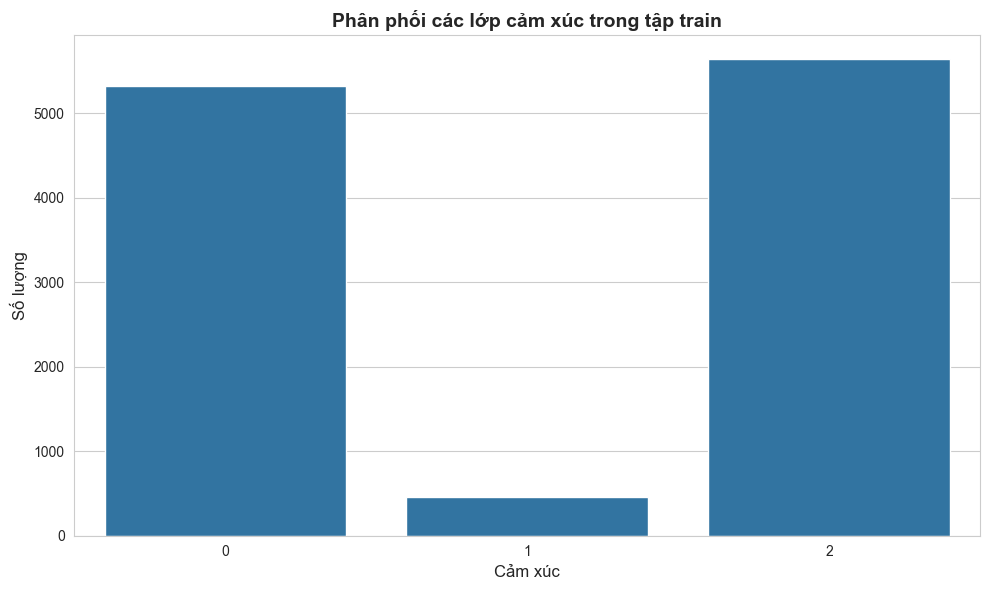

In [9]:
# TODO: Vẽ biểu đồ phân phối các lớp cảm xúc
# Gợi ý: Sử dụng countplot của seaborn
plt.figure(figsize=(10, 6))
sns.countplot(data=train_data, x='sentiment')

plt.title('Phân phối các lớp cảm xúc trong tập train', fontsize=14, fontweight='bold')
plt.xlabel('Cảm xúc', fontsize=12)
plt.ylabel('Số lượng', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
def preprocess_text(text):
    """
    Tiền xử lý văn bản tiếng Việt
    
    Args:
        text (str): Văn bản đầu vào
    
    Returns:
        str: Văn bản sau khi tiền xử lý
    """
    if not isinstance(text, str):
        return ""
    
    # TODO: Chuyển về chữ thường
    # Gợi ý: Sử dụng phương thức .lower()
    text = text.lower()
    
    # TODO: Loại bỏ URLs
    # Gợi ý: Sử dụng regex re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # TODO: Loại bỏ email
    # Gợi ý: re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    
    # TODO: Loại bỏ số
    # Gợi ý: re.sub(r'\d+', '', text)
    text = re.sub(r'\d+', '', text)
    
    # TODO: Loại bỏ dấu câu và ký tự đặc biệt (giữ lại khoảng trắng)
    # Gợi ý: re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    
    # TODO: Loại bỏ khoảng trắng thừa
    # Gợi ý: re.sub(r'\s+', ' ', text).strip()
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [12]:
def vietnamese_tokenize(text):
    """
    Tách từ tiếng Việt sử dụng underthesea
    
    Args:
        text (str): Văn bản đã tiền xử lý
    
    Returns:
        str: Văn bản đã được tách từ
    """
    try:
        # TODO: Sử dụng word_tokenize từ underthesea để tách từ
        # Gợi ý: word_tokenize(text)
        tokens = word_tokenize(text)
        return " ".join(tokens)
    except:
        return text

In [39]:
print("Đang tiền xử lý dữ liệu...")

# TODO: Áp dụng hàm preprocess_text cho cột 'sentence' trong train_data và test_data
# Gợi ý: Sử dụng .apply() với lambda function
train_data['processed_text'] = train_data['sentence'].apply(lambda x: preprocess_text(x))
test_data['processed_text'] = test_data['sentence'].apply(lambda x: preprocess_text(x))

# TODO: Áp dụng hàm vietnamese_tokenize cho 'processed_text'
train_data['tokenized_text'] = train_data['processed_text'].apply(lambda x: vietnamese_tokenize(x))
test_data['tokenized_text'] = test_data['processed_text'].apply(lambda x: vietnamese_tokenize(x))

print("Hoàn thành tiền xử lý!")

# Hiển thị ví dụ
print("\n=== VÍ DỤ SAU TIỀN XỬ LÝ ===")
print(f"Văn bản gốc: {train_data['sentence'].iloc[0]}")
print(f"Sau tiền xử lý: {train_data['processed_text'].iloc[0]}")
print(f"Sau tách từ: {train_data['tokenized_text'].iloc[0]}")

Đang tiền xử lý dữ liệu...
Hoàn thành tiền xử lý!

=== VÍ DỤ SAU TIỀN XỬ LÝ ===
Văn bản gốc: slide giáo trình đầy đủ .
Sau tiền xử lý: slide giáo trình đầy đủ
Sau tách từ: slide giáo trình đầy đủ


In [14]:
# TODO: Khởi tạo TfidfVectorizer với các tham số sau:
# - max_features=5000 (giới hạn 5000 từ phổ biến nhất)
# - ngram_range=(1, 2) (sử dụng unigram và bigram)
# - min_df=2 (từ phải xuất hiện ít nhất 2 lần)
# - max_df=0.9 (loại bỏ từ xuất hiện quá 90% văn bản)
# Gợi ý: tfidf_vectorizer = TfidfVectorizer(...)

tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.9)

In [15]:
# TODO: Fit vectorizer trên tập train và transform cả train và test
# Gợi ý: 
# X_train_tfidf = tfidf_vectorizer.fit_transform(train_data['tokenized_text'])
# X_test_tfidf = tfidf_vectorizer.transform(test_data['tokenized_text'])

X_train_tfidf = tfidf_vectorizer.fit_transform(train_data['tokenized_text'])
X_test_tfidf = tfidf_vectorizer.transform(test_data['tokenized_text'])

# Tạo nhãn
y_train = train_data['sentiment']
y_test = test_data['sentiment']

print(f"Kích thước X_train_tfidf: {X_train_tfidf.shape}")
print(f"Kích thước X_test_tfidf: {X_test_tfidf.shape}")
print(f"Số lượng từ trong vocabulary: {len(tfidf_vectorizer.vocabulary_)}")

Kích thước X_train_tfidf: (11426, 5000)
Kích thước X_test_tfidf: (3166, 5000)
Số lượng từ trong vocabulary: 5000


In [16]:
print("\n=== LOGISTIC REGRESSION ===")

# TODO: Khởi tạo mô hình LogisticRegression
# Tham số gợi ý:
# - max_iter=1000 (số vòng lặp tối đa)
# - random_state=42 (để tái tạo kết quả)
# - class_weight='balanced' (cân bằng lớp nếu dữ liệu mất cân bằng)
# Gợi ý: lr_model = LogisticRegression(...)

lr_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')


# TODO: Huấn luyện mô hình trên dữ liệu train
# Gợi ý: lr_model.fit(X_train_tfidf, y_train)

lr_model.fit(X_train_tfidf, y_train)


print("Hoàn thành huấn luyện Logistic Regression!")


=== LOGISTIC REGRESSION ===
Hoàn thành huấn luyện Logistic Regression!


In [18]:
# TODO: Dự đoán trên tập test
# Gợi ý: y_pred_lr = lr_model.predict(X_test_tfidf)

y_pred_lr = lr_model.predict(X_test_tfidf)


# TODO: Dự đoán xác suất (để tính AUC)
# Gợi ý: y_pred_proba_lr = lr_model.predict_proba(X_test_tfidf)

y_pred_proba_lr = lr_model.predict_proba(X_test_tfidf)

In [19]:
# TODO: Tính Accuracy
# Gợi ý: accuracy_score(y_test, y_pred_lr)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print(f"Accuracy: {lr_accuracy:.4f}")

# TODO: Tính F1-Score (macro average)
# Gợi ý: f1_score(y_test, y_pred_lr, average='macro')

lr_f1 = f1_score(y_test, y_pred_lr, average='macro')

print(f"F1-Score (Macro): {lr_f1:.4f}")

# TODO: In classification report
# Gợi ý: print(classification_report(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8579
F1-Score (Macro): 0.7167

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      1409
           1       0.28      0.49      0.36       167
           2       0.96      0.87      0.91      1590

    accuracy                           0.86      3166
   macro avg       0.70      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



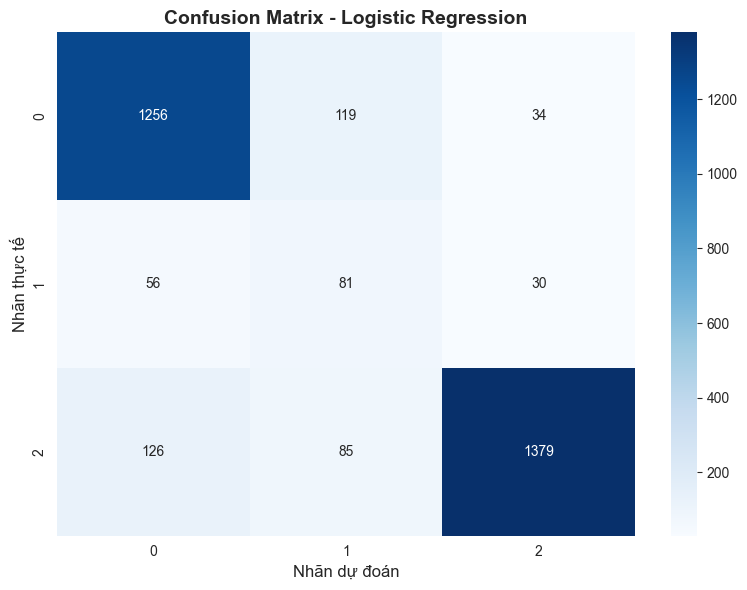

In [20]:
# TODO: Tính confusion matrix
# Gợi ý: confusion_matrix(y_test, y_pred_lr)

cm_lr = confusion_matrix(y_test, y_pred_lr)


# Vẽ confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', 
            xticklabels=lr_model.classes_, 
            yticklabels=lr_model.classes_)
plt.title('Confusion Matrix - Logistic Regression', fontsize=14, fontweight='bold')
plt.ylabel('Nhãn thực tế', fontsize=12)
plt.xlabel('Nhãn dự đoán', fontsize=12)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.preprocessing import label_binarize


AUC-ROC (Macro): 0.9309


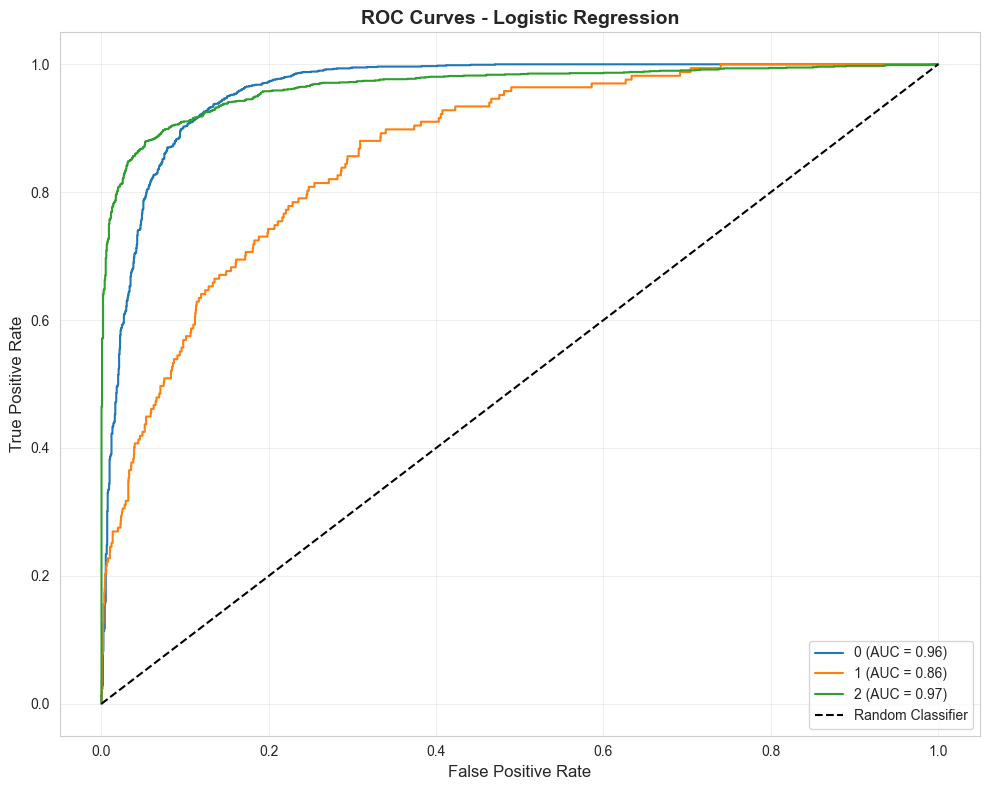

In [22]:
# Chuyển đổi nhãn sang dạng one-hot encoding
y_test_bin = label_binarize(y_test, classes=lr_model.classes_)

# TODO: Tính AUC cho từng lớp
# Gợi ý: Sử dụng roc_auc_score với average='macro' và multi_class='ovr'

lr_auc = roc_auc_score(y_test_bin, y_pred_proba_lr, average='macro', multi_class='ovr')

print(f"\nAUC-ROC (Macro): {lr_auc:.4f}")

# Vẽ ROC curve cho từng lớp
plt.figure(figsize=(10, 8))

for i, class_name in enumerate(lr_model.classes_):
    # TODO: Tính fpr, tpr cho từng lớp
    # Gợi ý: fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba_lr[:, i])
    
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba_lr[:, i])
    
    # TODO: Tính AUC cho lớp này
    # Gợi ý: roc_auc_score(y_test_bin[:, i], y_pred_proba_lr[:, i])
    
    class_auc = roc_auc_score(y_test_bin[:, i], y_pred_proba_lr[:, i])
    
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {class_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - Logistic Regression', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
print("\n=== SUPPORT VECTOR MACHINE (SVM) ===")

# TODO: Khởi tạo mô hình SVC
# Tham số gợi ý:
# - kernel='linear' (kernel tuyến tính)
# - probability=True (để tính xác suất cho AUC)
# - random_state=42
# - class_weight='balanced'
# Gợi ý: svm_model = SVC(...)

svm_model = SVC(kernel='linear', probability=True, random_state=42, class_weight='balanced')


# TODO: Huấn luyện mô hình trên dữ liệu train
# Lưu ý: SVM có thể mất thời gian với dữ liệu lớn

svm_model.fit(X_train_tfidf, y_train)


print("Hoàn thành huấn luyện SVM!")


=== SUPPORT VECTOR MACHINE (SVM) ===
Hoàn thành huấn luyện SVM!


In [24]:
# TODO: Dự đoán trên tập test

y_pred_svm = svm_model.predict(X_test_tfidf)


# TODO: Dự đoán xác suất

y_pred_proba_svm = svm_model.predict_proba(X_test_tfidf)

In [25]:
# TODO: Tính Accuracy

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"Accuracy: {svm_accuracy:.4f}")

# TODO: Tính F1-Score (macro average)

svm_f1 = f1_score(y_test, y_pred_svm, average='macro')

print(f"F1-Score (Macro): {svm_f1:.4f}")

# TODO: In classification report

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.8654
F1-Score (Macro): 0.7216

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      1409
           1       0.31      0.45      0.36       167
           2       0.95      0.87      0.91      1590

    accuracy                           0.87      3166
   macro avg       0.71      0.74      0.72      3166
weighted avg       0.88      0.87      0.87      3166



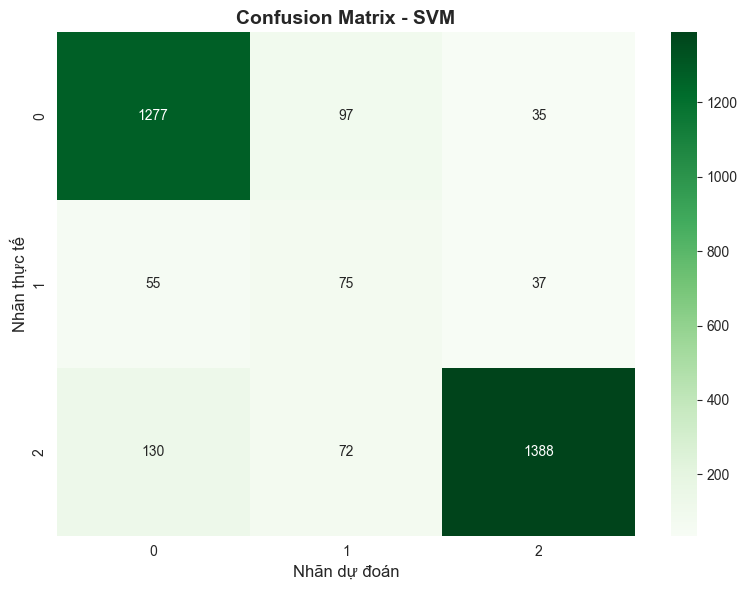

In [26]:
# TODO: Tính confusion matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)


# Vẽ confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens',
            xticklabels=svm_model.classes_,
            yticklabels=svm_model.classes_)
plt.title('Confusion Matrix - SVM', fontsize=14, fontweight='bold')
plt.ylabel('Nhãn thực tế', fontsize=12)
plt.xlabel('Nhãn dự đoán', fontsize=12)
plt.tight_layout()
plt.show()


AUC-ROC (Macro): 0.9322


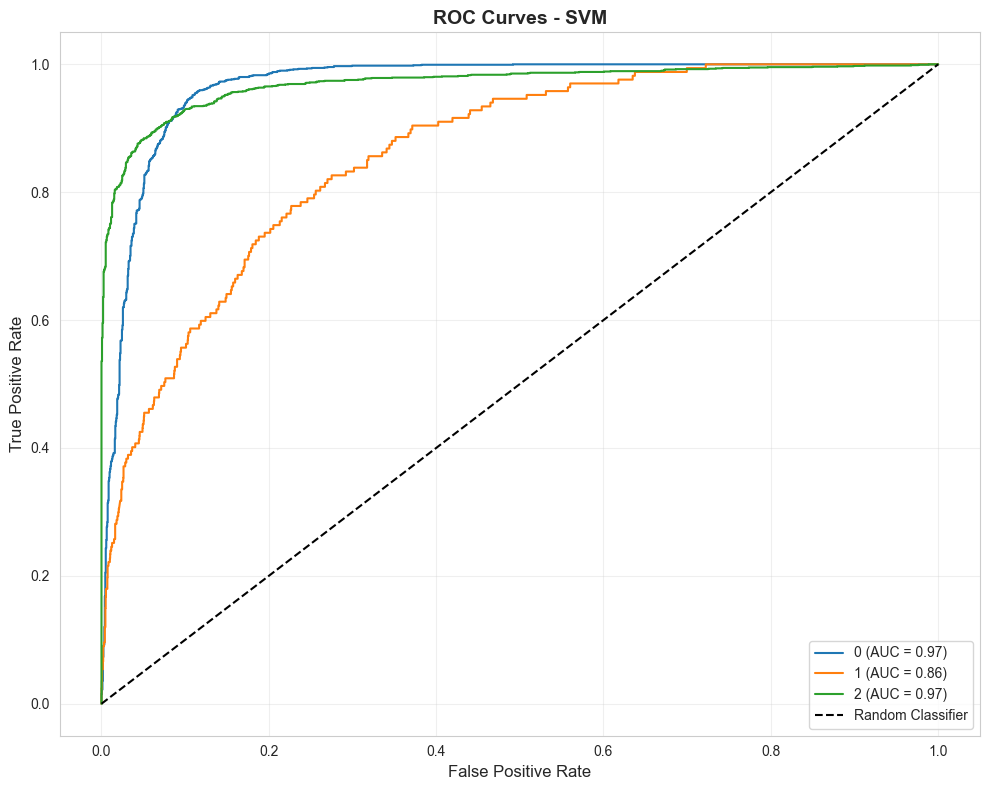

In [27]:
# TODO: Tính AUC cho SVM

svm_auc = roc_auc_score(y_test_bin, y_pred_proba_svm, average='macro', multi_class='ovr')

print(f"\nAUC-ROC (Macro): {svm_auc:.4f}")

# Vẽ ROC curve cho từng lớp
plt.figure(figsize=(10, 8))

for i, class_name in enumerate(svm_model.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba_svm[:, i])
    class_auc = roc_auc_score(y_test_bin[:, i], y_pred_proba_svm[:, i])
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {class_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - SVM', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# TODO: Tạo DataFrame để so sánh kết quả
# Gợi ý: Tạo dict với keys là tên model, values là dict của các metrics

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM'],
    'Accuracy': [lr_accuracy, svm_accuracy],
    'F1-Score': [lr_f1, svm_f1],
    'AUC-ROC': [lr_auc, svm_auc]
})

print("\n=== SO SÁNH KẾT QUẢ ===")
print(comparison_df.to_string(index=False))


=== SO SÁNH KẾT QUẢ ===
              Model  Accuracy  F1-Score  AUC-ROC
Logistic Regression  0.857865  0.716690 0.930876
                SVM  0.865445  0.721571 0.932236


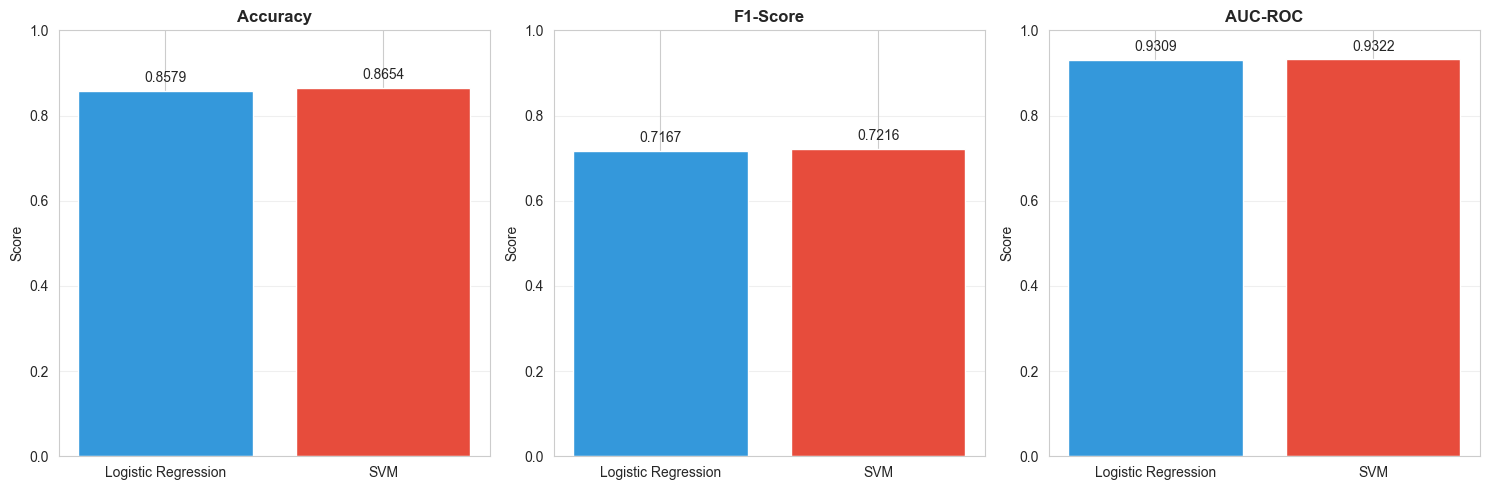

In [29]:
# Vẽ biểu đồ so sánh
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ['Accuracy', 'F1-Score', 'AUC-ROC']
colors = ['#3498db', '#e74c3c']

for idx, metric in enumerate(metrics):
    # TODO: Vẽ bar chart cho từng metric
    # Gợi ý: axes[idx].bar(comparison_df['Model'], comparison_df[metric], color=colors)
    
    # Code của bạn
    axes[idx].bar(comparison_df['Model'], comparison_df[metric], color=colors)
    
    axes[idx].set_title(metric, fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Score', fontsize=10)
    axes[idx].set_ylim([0, 1])
    axes[idx].grid(axis='y', alpha=0.3)
    
    # Thêm giá trị lên cột
    for i, v in enumerate(comparison_df[metric]):
        axes[idx].text(i, v + 0.02, f'{v:.4f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

In [31]:
def predict_sentiment(text, model, vectorizer):
    """
    Dự đoán cảm xúc cho văn bản mới
    
    Args:
        text (str): Văn bản cần dự đoán
        model: Mô hình đã huấn luyện
        vectorizer: TF-IDF vectorizer đã fit
    
    Returns:
        tuple: (nhãn dự đoán, xác suất)
    """
    # TODO: Tiền xử lý văn bản
    processed = preprocess_text(text)
    tokenized = vietnamese_tokenize(processed)
    
    # TODO: Chuyển đổi sang TF-IDF vector
    # Gợi ý: vectorizer.transform([tokenized])
    text_vector = vectorizer.transform([tokenized])
    
    # TODO: Dự đoán
    prediction = model.predict(text_vector)
    probability = model.predict_proba(text_vector)
    
    return prediction[0], probability[0]

In [32]:
# Các câu test
test_sentences = [
    "Giảng viên dạy rất hay và dễ hiểu, tôi rất thích môn học này",
    "Chương trình học quá nặng, áp lực quá nhiều",
    "Cơ sở vật chất bình thường, không có gì đặc biệt",
    "Thư viện có nhiều sách hay, phục vụ tốt",
    "Thầy cô không nhiệt tình, giảng dạy nhàm chán"
]

print("\n=== KIỂM THỬ VỚI LOGISTIC REGRESSION ===")
for sentence in test_sentences:
    pred, prob = predict_sentiment(sentence, lr_model, tfidf_vectorizer)
    print(f"\nVăn bản: {sentence}")
    print(f"Dự đoán: {pred}")
    print(f"Xác suất: {dict(zip(lr_model.classes_, prob))}")

print("\n=== KIỂM THỬ VỚI SVM ===")
for sentence in test_sentences:
    pred, prob = predict_sentiment(sentence, svm_model, tfidf_vectorizer)
    print(f"\nVăn bản: {sentence}")
    print(f"Dự đoán: {pred}")
    print(f"Xác suất: {dict(zip(svm_model.classes_, prob))}")


=== KIỂM THỬ VỚI LOGISTIC REGRESSION ===

Văn bản: Giảng viên dạy rất hay và dễ hiểu, tôi rất thích môn học này
Dự đoán: 2
Xác suất: {np.int64(0): np.float64(0.005785988769240726), np.int64(1): np.float64(0.0006226099912619524), np.int64(2): np.float64(0.9935914012394972)}

Văn bản: Chương trình học quá nặng, áp lực quá nhiều
Dự đoán: 0
Xác suất: {np.int64(0): np.float64(0.9341524706415225), np.int64(1): np.float64(0.01265637744534414), np.int64(2): np.float64(0.0531911519131335)}

Văn bản: Cơ sở vật chất bình thường, không có gì đặc biệt
Dự đoán: 1
Xác suất: {np.int64(0): np.float64(0.17631380488286896), np.int64(1): np.float64(0.8120683374091263), np.int64(2): np.float64(0.011617857708004555)}

Văn bản: Thư viện có nhiều sách hay, phục vụ tốt
Dự đoán: 2
Xác suất: {np.int64(0): np.float64(0.19731606218676576), np.int64(1): np.float64(0.13488599247354277), np.int64(2): np.float64(0.6677979453396914)}

Văn bản: Thầy cô không nhiệt tình, giảng dạy nhàm chán
Dự đoán: 0
Xác suất: {np.int6

In [35]:
# Lấy các từ quan trọng nhất cho mỗi lớp
feature_names = tfidf_vectorizer.get_feature_names_out()
n_top_words = 10

print("\n=== TỪ QUAN TRỌNG NHẤT CHO MỖI LỚP (LOGISTIC REGRESSION) ===")

for i, class_name in enumerate(lr_model.classes_):
    # TODO: Lấy coefficients của lớp i
    # Gợi ý: lr_model.coef_[i]
    
    coef = lr_model.coef_[i]
    
    # TODO: Lấy indices của top n_top_words từ có coefficient cao nhất
    # Gợi ý: np.argsort(coef)[-n_top_words:][::-1]
    
    top_indices = np.argsort(coef)[-n_top_words:][::-1]
    
    # Lấy tên các từ
    top_words = [feature_names[idx] for idx in top_indices]
    top_coefs = [coef[idx] for idx in top_indices]
    
    print(f"\nLỚP {class_name}:")
    for word, score in zip(top_words, top_coefs):
        print(f"  {word}: {score:.4f}")


=== TỪ QUAN TRỌNG NHẤT CHO MỖI LỚP (LOGISTIC REGRESSION) ===

LỚP 0:
  nên: 6.8005
  cần: 5.8343
  chưa: 5.5130
  khó: 4.9979
  hơn: 4.2564
  quá: 3.9809
  ít: 3.3613
  hơi: 3.1865
  không: 3.1740
  nghỉ: 2.6774

LỚP 1:
  dung ôn: 2.3104
  không có: 2.0658
  giống: 1.9898
  ơn: 1.8616
  rộng kiến: 1.8113
  không: 1.7853
  nhưng không: 1.6597
  rất hiền: 1.6043
  trong các: 1.5765
  fraction: 1.5608

LỚP 2:
  rất: 4.5411
  tốt: 4.5032
  hay: 3.9423
  dễ hiểu: 3.6507
  tình: 3.5418
  vui: 3.4737
  nhiệt: 3.3399
  tận: 2.9365
  nhiệt tình: 2.8162
  hiểu: 2.5973


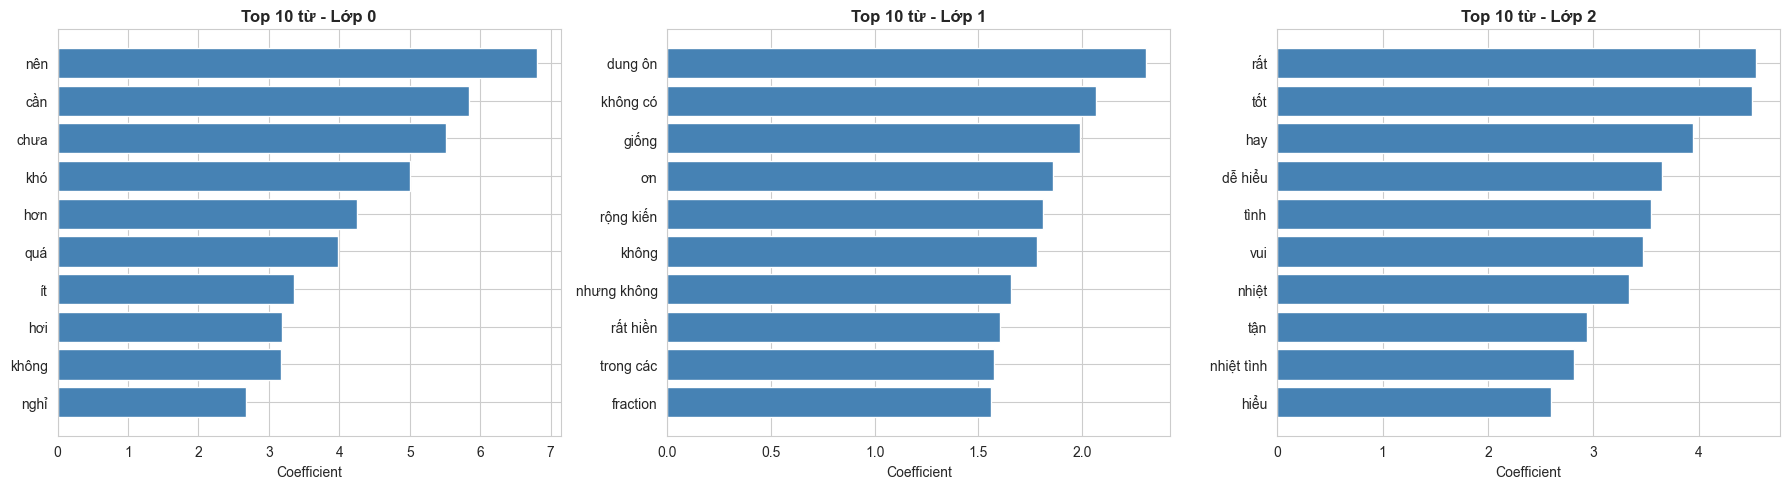

In [36]:
# Vẽ biểu đồ cho mỗi lớp
fig, axes = plt.subplots(1, len(lr_model.classes_), figsize=(18, 5))

for i, class_name in enumerate(lr_model.classes_):
    coef = lr_model.coef_[i]
    top_indices = np.argsort(coef)[-n_top_words:][::-1]
    top_words = [feature_names[idx] for idx in top_indices]
    top_coefs = [coef[idx] for idx in top_indices]
    
    axes[i].barh(range(n_top_words), top_coefs, color='steelblue')
    axes[i].set_yticks(range(n_top_words))
    axes[i].set_yticklabels(top_words)
    axes[i].set_xlabel('Coefficient', fontsize=10)
    axes[i].set_title(f'Top {n_top_words} từ - Lớp {class_name}', fontsize=12, fontweight='bold')
    axes[i].invert_yaxis()

plt.tight_layout()
plt.show()

In [38]:
print("\n" + "="*70)
print("KẾT LUẬN")
print("="*70)

print("""
1. TF-IDF và Phân loại Văn bản:
   - TF-IDF đã chuyển đổi thành công văn bản tiếng Việt thành vector số
   - Bigram giúp nắm bắt được ngữ cảnh tốt hơn so với chỉ dùng unigram

2. So sánh Mô hình:
""")

# TODO: Viết nhận xét so sánh dựa trên kết quả
if lr_accuracy > svm_accuracy:
    print("   - Logistic Regression có Accuracy cao hơn SVM")
else:
    print("   - SVM có Accuracy cao hơn Logistic Regression")

if lr_f1 > svm_f1:
    print("   - Logistic Regression có F1-Score tốt hơn SVM")
else:
    print("   - SVM có F1-Score tốt hơn Logistic Regression")

print("""
3. Ưu và Nhược điểm:
   
   Logistic Regression:
   - Ưu điểm: Nhanh, dễ giải thích, hiệu quả với dữ liệu tuyến tính
   - Nhược điểm: Giả định tuyến tính có thể không phù hợp với dữ liệu phức tạp
   
   SVM:
   - Ưu điểm: Hiệu quả với không gian nhiều chiều, robust với outliers
   - Nhược điểm: Chậm với dataset lớn, khó giải thích

4. Hướng cải thiện:
   - Thử các kỹ thuật embedding khác: Word2Vec, FastText, PhoBERT
   - Hyperparameter tuning với GridSearchCV hoặc RandomizedSearchCV
   - Xử lý dữ liệu mất cân bằng tốt hơn (SMOTE, class weights)
   - Thử các mô hình deep learning: LSTM, CNN, Transformer
""")

print("="*70)


KẾT LUẬN

1. TF-IDF và Phân loại Văn bản:
   - TF-IDF đã chuyển đổi thành công văn bản tiếng Việt thành vector số
   - Bigram giúp nắm bắt được ngữ cảnh tốt hơn so với chỉ dùng unigram

2. So sánh Mô hình:

   - SVM có Accuracy cao hơn Logistic Regression
   - SVM có F1-Score tốt hơn Logistic Regression

3. Ưu và Nhược điểm:
   
   Logistic Regression:
   - Ưu điểm: Nhanh, dễ giải thích, hiệu quả với dữ liệu tuyến tính
   - Nhược điểm: Giả định tuyến tính có thể không phù hợp với dữ liệu phức tạp
   
   SVM:
   - Ưu điểm: Hiệu quả với không gian nhiều chiều, robust với outliers
   - Nhược điểm: Chậm với dataset lớn, khó giải thích

4. Hướng cải thiện:
   - Thử các kỹ thuật embedding khác: Word2Vec, FastText, PhoBERT
   - Hyperparameter tuning với GridSearchCV hoặc RandomizedSearchCV
   - Xử lý dữ liệu mất cân bằng tốt hơn (SMOTE, class weights)
   - Thử các mô hình deep learning: LSTM, CNN, Transformer

